In [81]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Analisi degli scarti produttivi

`Domanda/e di business:`
* Quali linee scartano di più? 
* Queste perdite di resa sono attribuibili?

## Per linea e turno

In [2]:
cd = os.getcwd()
cd = os.chdir("../data")
df = pd.read_csv("fact_produzione.csv")
# df

In [3]:
df["turno"] = df["turno"].str.replace({"Mattina" :    "1. Mattina",
                         "Pomeriggio" : "2. Pomeriggio",
                         "Notte" :      "3. Notte"})

In [4]:
scarti_linea = df.groupby("linea_id")[["kg_input", "kg_output_conforme", "kg_scarto"]].sum().reset_index()
scarti_linea["calculated_input"] = scarti_linea["kg_output_conforme"] + scarti_linea["kg_scarto"]
scarti_linea["check"] = scarti_linea["calculated_input"] != scarti_linea["kg_input"]
scarti_linea["diff"] = scarti_linea["calculated_input"] - scarti_linea["kg_input"]
scarti_linea["resa"] = scarti_linea["kg_output_conforme"] / scarti_linea["kg_input"]
# scarti_linea

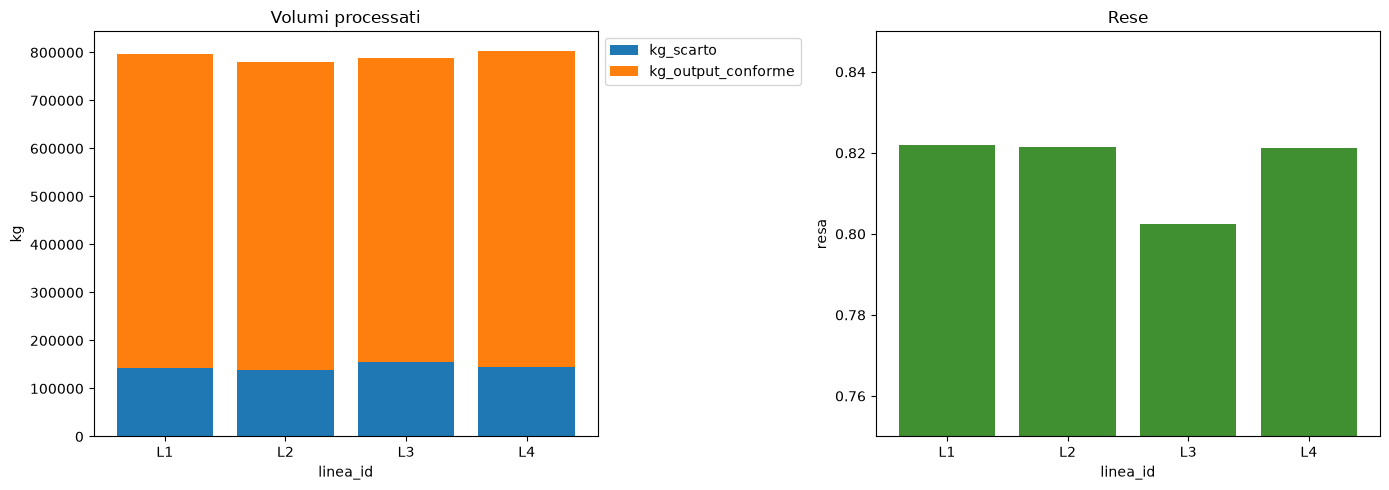

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Sinistra
ax1.bar(scarti_linea["linea_id"], scarti_linea["kg_scarto"], label='kg_scarto')
ax1.bar(scarti_linea["linea_id"], scarti_linea["kg_output_conforme"], bottom=scarti_linea["kg_scarto"], label='kg_output_conforme')
ax1.set_xlabel('linea_id')
ax1.set_ylabel('kg')
ax1.legend(bbox_to_anchor=(1, 1), loc="upper left")
ax1.set_title("Volumi processati")

# Destra
ax2.bar(scarti_linea["linea_id"], scarti_linea["resa"], label='resa', color="#408f30")
ax2.set_title("Rese")
ax2.set_xlabel('linea_id')
ax2.set_ylabel('resa')
ax2.set_ylim(0.75, 0.85)

plt.tight_layout()
plt.show()

Confronto per turno

In [6]:
scarti_turno = df.groupby("turno")[["kg_input", "kg_output_conforme", "kg_scarto"]].sum().reset_index()
scarti_turno["calculated_input"] = scarti_turno["kg_output_conforme"] + scarti_turno["kg_scarto"]
scarti_turno["check"] = scarti_turno["calculated_input"] != scarti_turno["kg_input"]
scarti_turno["diff"] = scarti_turno["calculated_input"] - scarti_turno["kg_input"]
scarti_turno["resa"] = scarti_turno["kg_output_conforme"] / scarti_turno["kg_input"]
# scarti_turno

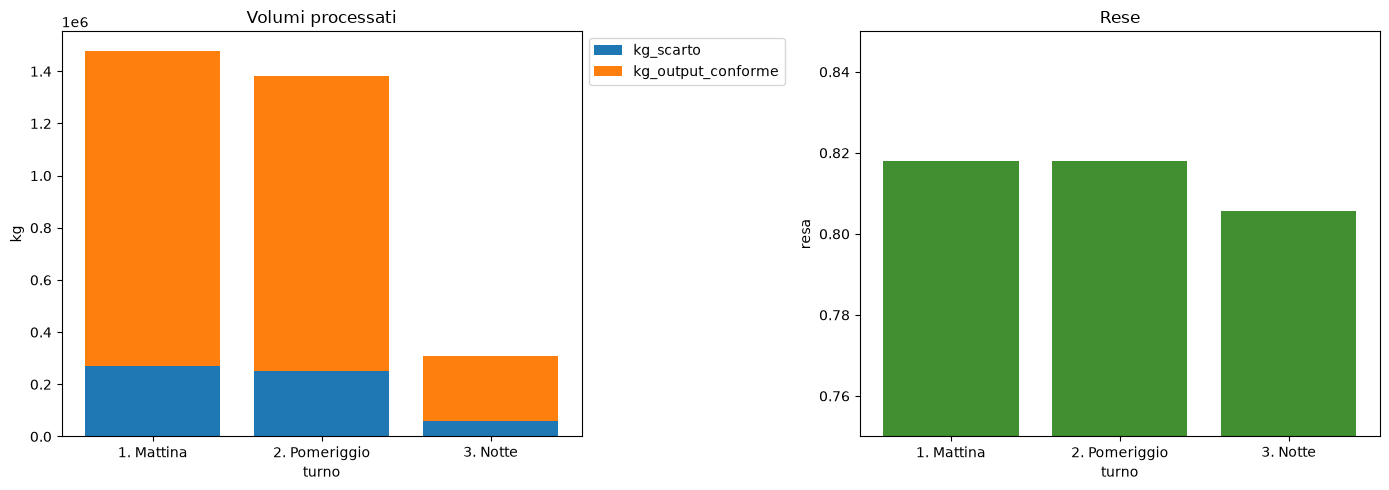

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Sinistra
ax1.bar(scarti_turno["turno"], scarti_turno["kg_scarto"], label='kg_scarto')
ax1.bar(scarti_turno["turno"], scarti_turno["kg_output_conforme"], bottom=scarti_turno["kg_scarto"], label='kg_output_conforme')
ax1.set_xlabel('turno')
ax1.set_ylabel('kg')
ax1.legend(bbox_to_anchor=(1, 1), loc="upper left")
ax1.set_title("Volumi processati")

# Destra
ax2.bar(scarti_turno["turno"], scarti_turno["resa"], label='resa', color="#408f30")
ax2.set_title("Rese")
ax2.set_xlabel('turno')
ax2.set_ylabel('resa')
ax2.set_ylim(0.75, 0.85)

plt.tight_layout()
plt.show()

L'informazione combinata è quindi

In [8]:
scarti_linea_turno = df.groupby(["linea_id", "turno"])[["kg_input", "kg_output_conforme", "kg_scarto"]].sum().reset_index()
scarti_linea_turno["calculated_input"] = scarti_linea_turno["kg_output_conforme"] + scarti_linea_turno["kg_scarto"]
scarti_linea_turno["check"] = scarti_linea_turno["calculated_input"] != scarti_linea_turno["kg_input"]
scarti_linea_turno["diff"] = scarti_linea_turno["calculated_input"] - scarti_linea_turno["kg_input"]
scarti_linea_turno["resa"] = scarti_linea_turno["kg_output_conforme"] / scarti_linea_turno["kg_input"]
# scarti_linea_turno

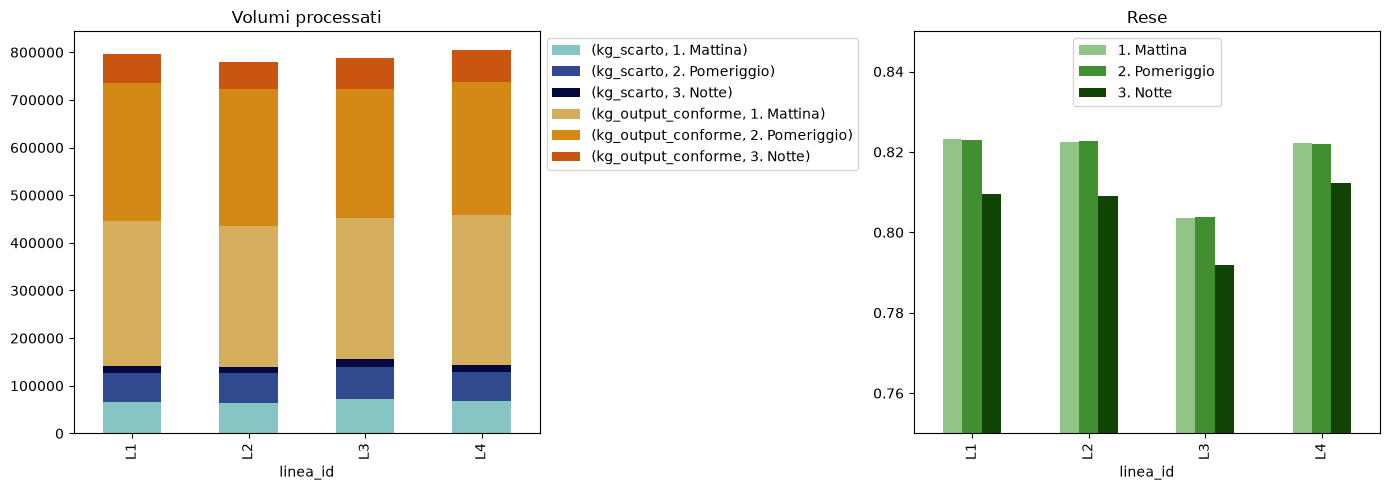

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Volumi: barre affiancate per turno, raggruppate per linea
volumi = scarti_linea_turno.pivot(
    index="linea_id",
    columns="turno",
    values=["kg_scarto", "kg_output_conforme"]
)

volumi.plot(kind="bar", ax=ax1, stacked=True, color=["#87c5c5", "#30498f", "#03093f",
                                                     "#d4ae5c", "#d48917", "#ca5510"])
ax1.legend(bbox_to_anchor=(1, 1), loc="upper left")
ax1.set_title("Volumi processati")

# Rese: una barra per turno dentro ogni linea
rese = scarti_linea_turno.pivot(
    index="linea_id",
    columns="turno",
    values="resa"
)

rese.plot(kind="bar", ax=ax2, color=["#91c587", "#408f30", "#0f4405"])
ax2.set_title("Rese")
ax2.set_ylim(0.75, 0.85)
ax2.legend(loc="upper center")

plt.tight_layout()
plt.show()

Una volta stabilito che:
* tutti i turni notturni hanno una resa inferiore
* la linea 3 ha rese inferiori

Possiamo andare a studiare la situazione a livello di prodotto

## Per prodotto

In [10]:
prodotti = pd.read_csv("dim_prodotti.csv")
# prodotti

In [11]:
produzione_prodotti = df.merge(prodotti, on="sku")

In [12]:
scarti_famiglia = produzione_prodotti.groupby("famiglia")[["kg_input", "kg_output_conforme", "kg_scarto"]].sum().reset_index()
scarti_famiglia["calculated_input"] = scarti_famiglia["kg_output_conforme"] + scarti_famiglia["kg_scarto"]
scarti_famiglia["check"] = scarti_famiglia["calculated_input"] != scarti_famiglia["kg_input"]
scarti_famiglia["diff"] = scarti_famiglia["calculated_input"] - scarti_famiglia["kg_input"]
scarti_famiglia["resa"] = scarti_famiglia["kg_output_conforme"] / scarti_famiglia["kg_input"]
# scarti_famiglia

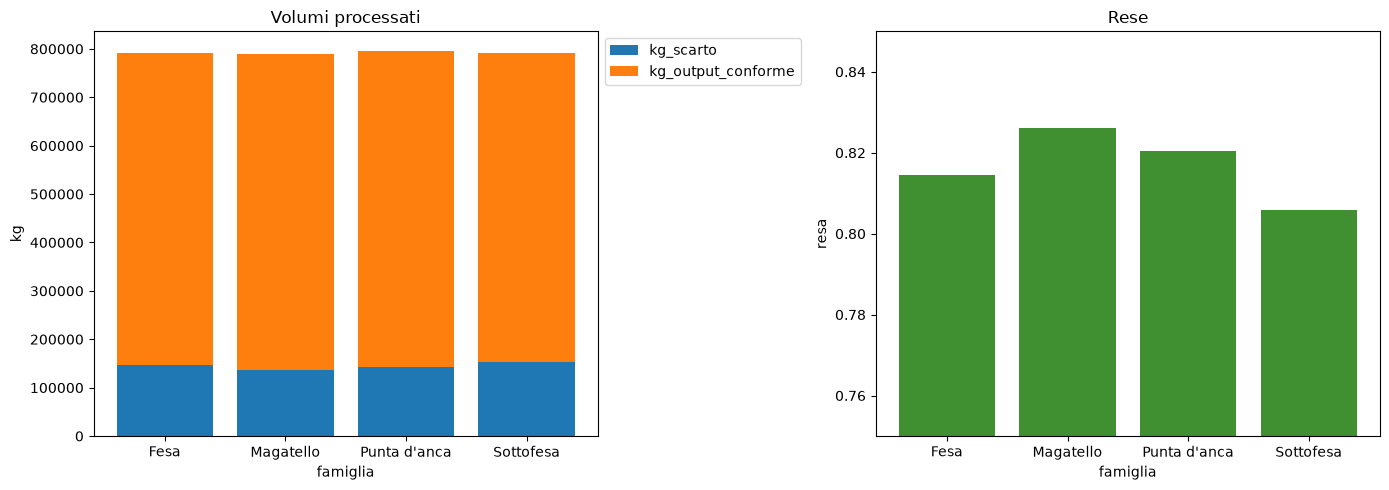

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Sinistra
ax1.bar(scarti_famiglia["famiglia"], scarti_famiglia["kg_scarto"], label='kg_scarto')
ax1.bar(scarti_famiglia["famiglia"], scarti_famiglia["kg_output_conforme"], bottom=scarti_famiglia["kg_scarto"], label='kg_output_conforme')
ax1.set_xlabel('famiglia')
ax1.set_ylabel('kg')
ax1.legend(bbox_to_anchor=(1, 1), loc="upper left")
ax1.set_title("Volumi processati")

# Destra
ax2.bar(scarti_famiglia["famiglia"], scarti_famiglia["resa"], label='resa', color="#408f30")
ax2.set_title("Rese")
ax2.set_xlabel('famiglia')
ax2.set_ylabel('resa')
ax2.set_ylim(0.75, 0.85)

plt.tight_layout()
plt.show()

In [14]:
scarti_famiglia_formato = produzione_prodotti.groupby(["famiglia", "formato"])[["kg_input", "kg_output_conforme", "kg_scarto"]].sum().reset_index()
scarti_famiglia_formato["calculated_input"] = scarti_famiglia_formato["kg_output_conforme"] + scarti_famiglia_formato["kg_scarto"]
scarti_famiglia_formato["check"] = scarti_famiglia_formato["calculated_input"] != scarti_famiglia_formato["kg_input"]
scarti_famiglia_formato["diff"] = scarti_famiglia_formato["calculated_input"] - scarti_famiglia_formato["kg_input"]
scarti_famiglia_formato["resa"] = scarti_famiglia_formato["kg_output_conforme"] / scarti_famiglia_formato["kg_input"]
# scarti_famiglia_formato

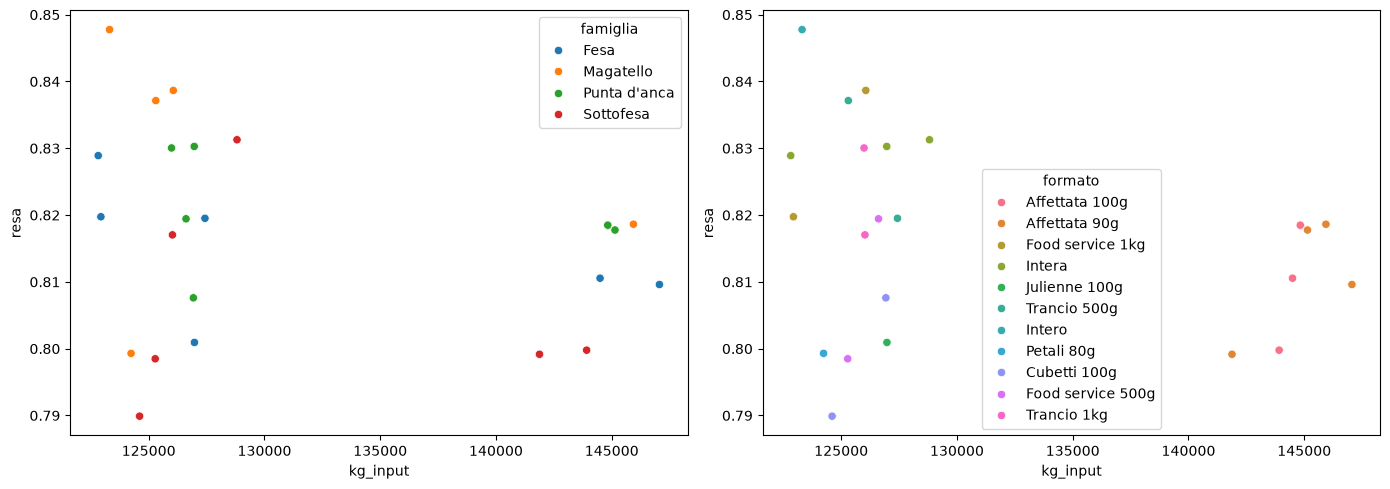

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Sinistra
sns.scatterplot(data=scarti_famiglia_formato, x="kg_input", y="resa", hue="famiglia", ax=ax1)

# Destra
sns.scatterplot(data=scarti_famiglia_formato, x="kg_input", y="resa", hue="formato", ax=ax2)

plt.tight_layout()
plt.show()

Quindi se distinguiamo anche a livello di formato, si nota che hanno volumi maggiori gli affettati a 90 e 100 g ma non sembrano esserci stratificazioni sulla resa

A questo punto posso andare a controllare:
* se di notte gli scarti sono più alti perchè viene processato sempre un certo prodotto/famiglia
* perchè vengono scartati (controllo qualità)
* se di notte ci sono più fermi macchine e se sono più lunghi perchè i manutentori sono in reperibilità e ci mettono più tempo ad intervenire

In [16]:
scarti_famiglia_turno = produzione_prodotti.groupby(["famiglia", "turno"])[["kg_input", "kg_output_conforme", "kg_scarto"]].sum().reset_index()
scarti_famiglia_turno["calculated_input"] = scarti_famiglia_turno["kg_output_conforme"] + scarti_famiglia_turno["kg_scarto"]
scarti_famiglia_turno["check"] = scarti_famiglia_turno["calculated_input"] != scarti_famiglia_turno["kg_input"]
scarti_famiglia_turno["diff"] = scarti_famiglia_turno["calculated_input"] - scarti_famiglia_turno["kg_input"]
scarti_famiglia_turno["resa"] = scarti_famiglia_turno["kg_output_conforme"] / scarti_famiglia_turno["kg_input"]
# scarti_famiglia_turno

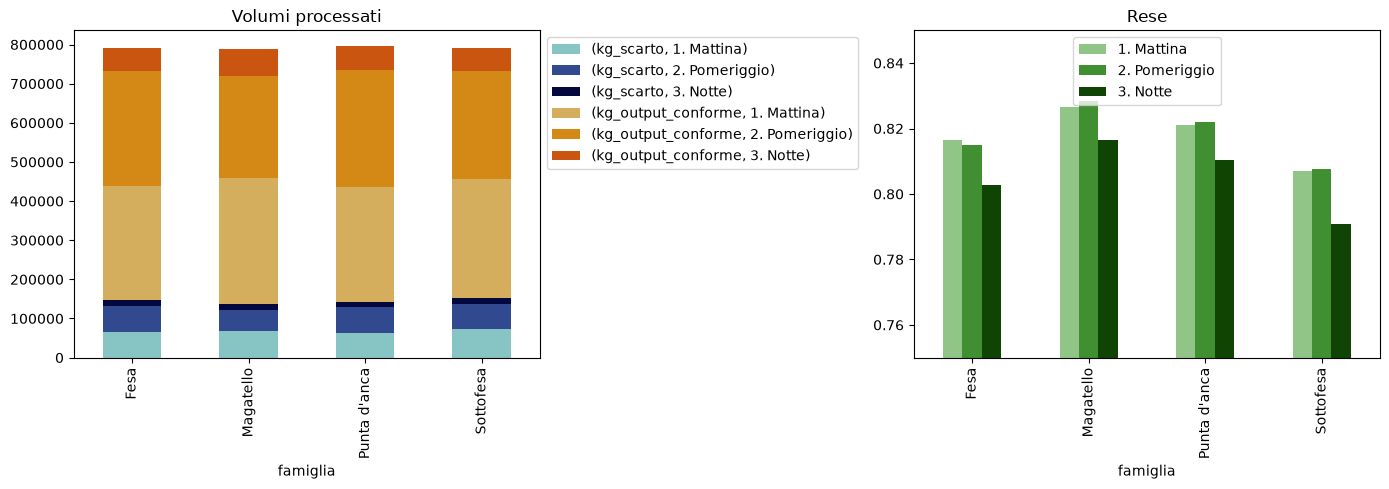

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Volumi: barre affiancate per turno, raggruppate per linea
volumi = scarti_famiglia_turno.pivot(
    index="famiglia",
    columns="turno",
    values=["kg_scarto", "kg_output_conforme"]
)

volumi.plot(kind="bar", ax=ax1, stacked=True, color=["#87c5c5", "#30498f", "#03093f",
                                                     "#d4ae5c", "#d48917", "#ca5510"])
ax1.legend(bbox_to_anchor=(1, 1), loc="upper left")
ax1.set_title("Volumi processati")

# Rese: una barra per turno dentro ogni linea
rese = scarti_famiglia_turno.pivot(
    index="famiglia",
    columns="turno",
    values="resa"
)

rese.plot(kind="bar", ax=ax2, color=["#91c587", "#408f30", "#0f4405"])
ax2.set_title("Rese")
ax2.set_ylim(0.75, 0.85)
ax2.legend(loc="upper center")

plt.tight_layout()
plt.show()

## Trend

In [18]:
df["anno-mese"] = df["data_produzione"].str[:7]
scarti_linea_trend = df.groupby(["anno-mese", "linea_id"])[["kg_input", "kg_output_conforme", "kg_scarto"]].sum().reset_index()
scarti_linea_trend["resa"] = scarti_linea_trend["kg_output_conforme"] / scarti_linea_trend["kg_input"]
# scarti_linea_trend

<Axes: xlabel='anno-mese', ylabel='resa'>

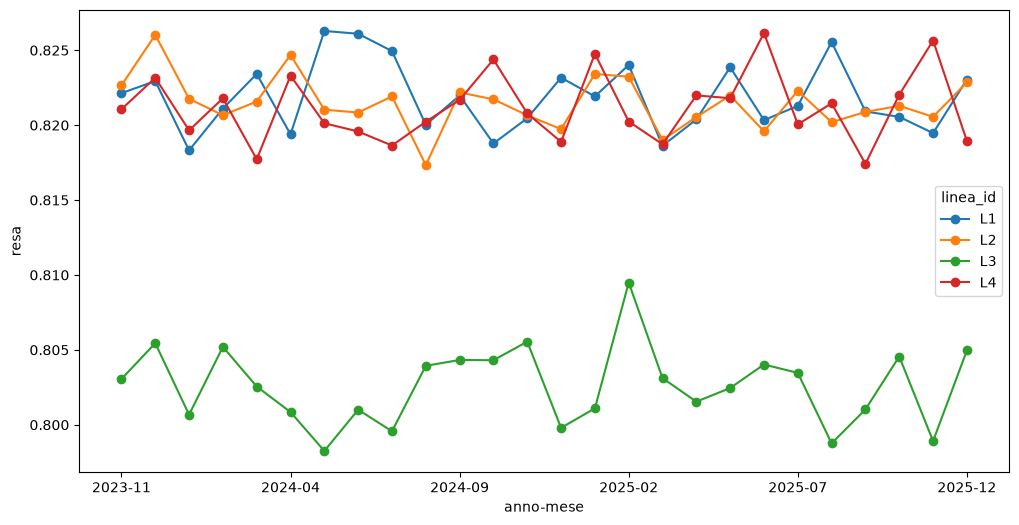

In [19]:
scarti_linea_trend_plot = scarti_linea_trend.pivot(
                                                    index="anno-mese",
                                                    columns="linea_id",
                                                    values="resa"
                                                    )

scarti_linea_trend_plot.plot(
    kind="line",
    x=None,
    ylabel="resa",
    xlabel="anno-mese",
    figsize=(12, 6),
    marker="o"
)

## Controlli qualità

Controlli qualità e ragione degli scarti

In [20]:
qualita = pd.read_csv("fact_qualita.csv")
# qualita.head(5)

In [21]:
conformi = qualita["controllo_id"].loc[qualita["esito"] == "Conforme"].count()
non_conformi = qualita["controllo_id"].loc[qualita["esito"] == "Non conforme"].count()
pct_conformi = round(conformi / (conformi + non_conformi), 3)
pct_non_conformi = round(1 - pct_conformi, 3)
print(f"La frazione di conformi è {pct_conformi}, mentre i non conformi sono {pct_non_conformi}")

La frazione di conformi è 0.957, mentre i non conformi sono 0.043


In [22]:
lotti_difettosi = qualita.loc[qualita["esito"] == "Non conforme"]
lotti_difettosi_causale = lotti_difettosi.groupby("causale")["controllo_id"].count().sort_values(ascending=False).to_frame().reset_index()
# lotti_difettosi_causale

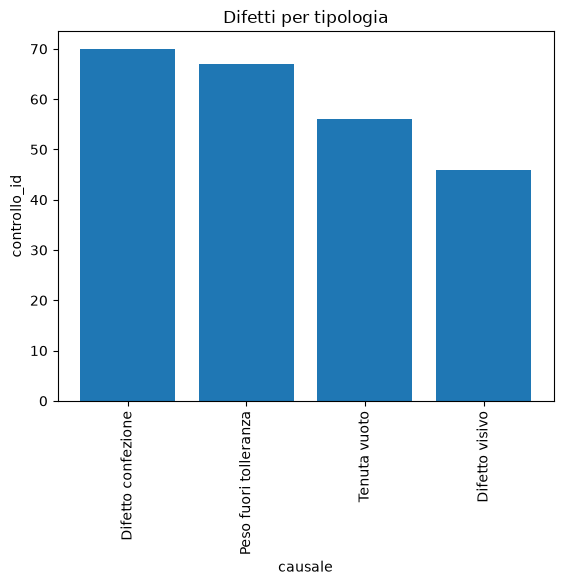

In [23]:
plt.bar(lotti_difettosi_causale["causale"], lotti_difettosi_causale["controllo_id"])
plt.xticks(rotation=90)
plt.title("Difetti per tipologia")
plt.xlabel("causale")
plt.ylabel("controllo_id")
plt.show()

In [24]:
lotti_difettosi_linea = lotti_difettosi.groupby("linea_id")["controllo_id"].count().sort_values(ascending=False).to_frame().reset_index()
# lotti_difettosi_linea

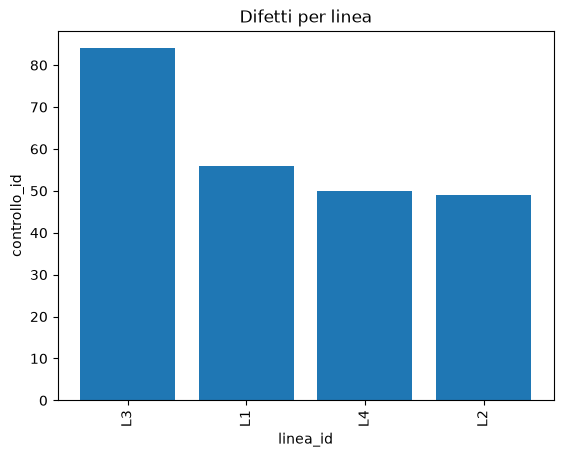

In [25]:
plt.bar(lotti_difettosi_linea["linea_id"], lotti_difettosi_linea["controllo_id"])
plt.xticks(rotation=90)
plt.title("Difetti per linea")
plt.xlabel("linea_id")
plt.ylabel("controllo_id")
plt.show()

In [26]:
lotti_difettosi_linea_causale = lotti_difettosi.groupby(["linea_id", "causale"])["controllo_id"].count().to_frame().reset_index()
# lotti_difettosi_linea_causale

<Axes: xlabel='linea_id'>

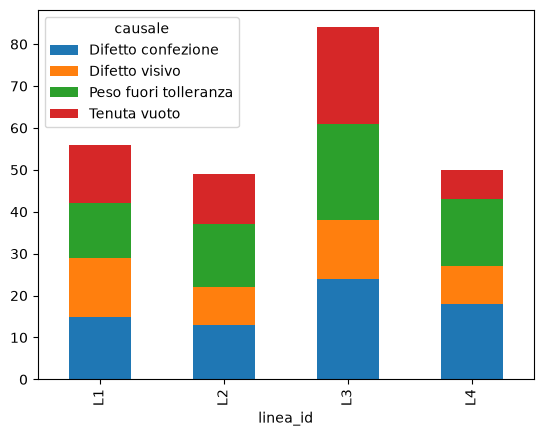

In [27]:
lotti_difettosi_linea_causale_plot = lotti_difettosi_linea_causale.pivot(
    index="linea_id",
    columns="causale",
    values="controllo_id"
)

lotti_difettosi_linea_causale_plot.plot(kind="bar", stacked=True)

Lotti difettosi per famiglia di prodotti (4 grafici affiancati)

In [28]:
lotti_difettosi_famiglia = lotti_difettosi.merge(prodotti, on="sku", how="left")
lotti_difettosi_famiglia_group = lotti_difettosi_famiglia.groupby(["linea_id", "famiglia", "causale"])["controllo_id"].count().to_frame().reset_index()
# lotti_difettosi_famiglia_group

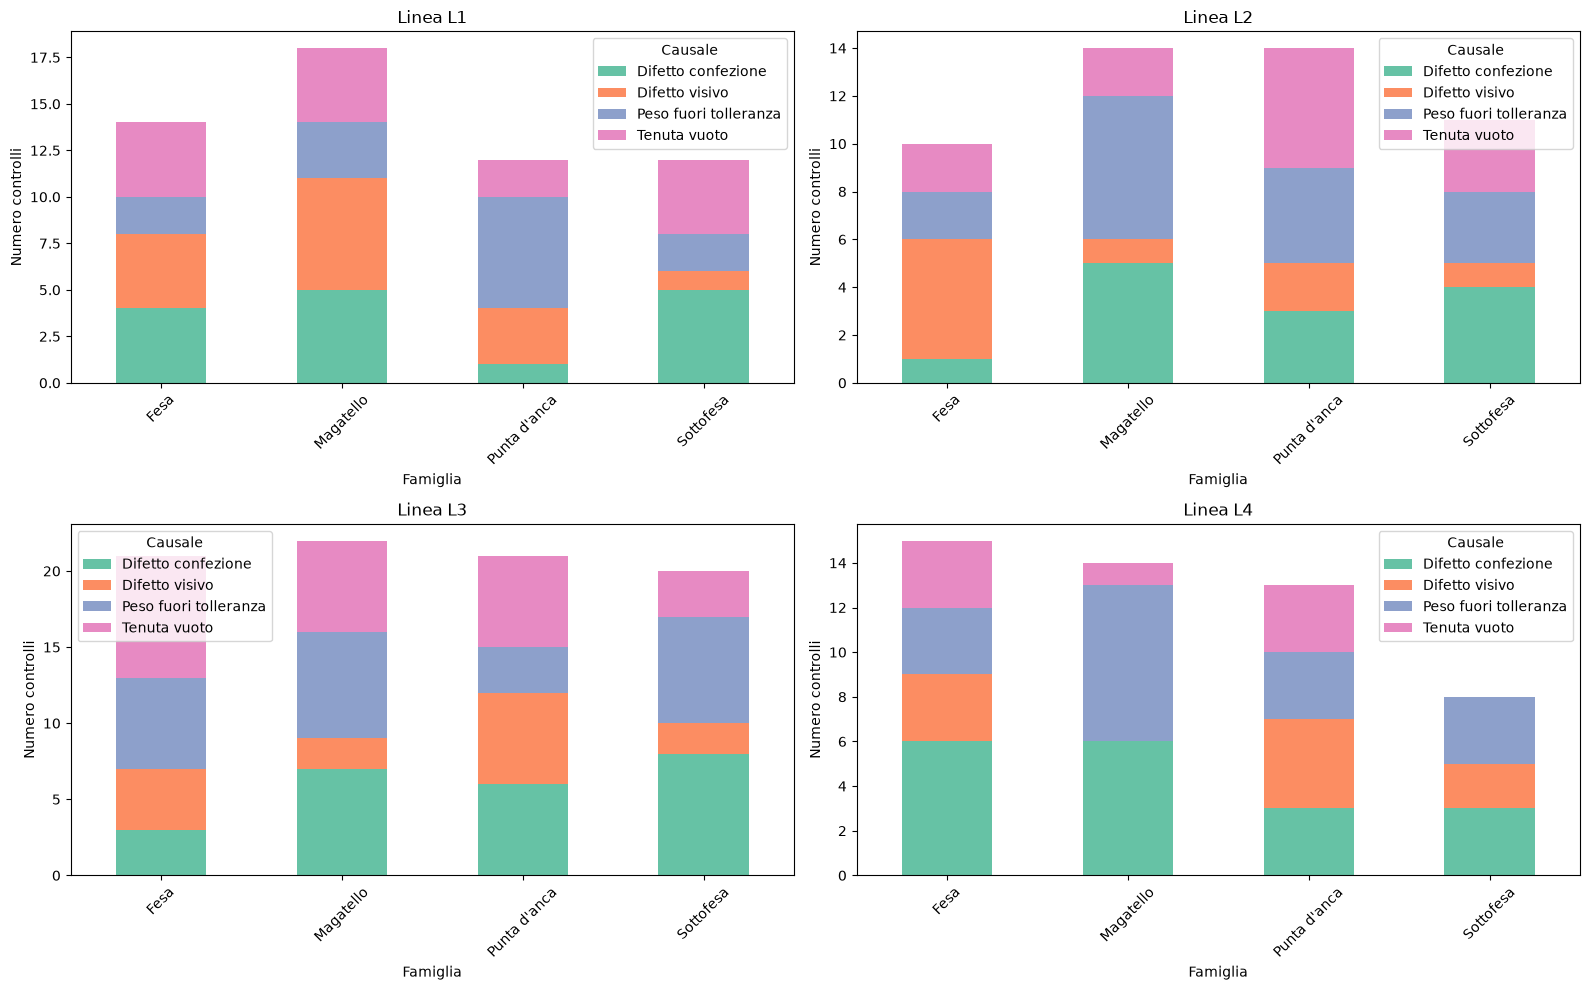

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

# Colori per le diverse causali
colori = sns.color_palette("Set2", n_colors=lotti_difettosi_famiglia_group["causale"].nunique())

for ax, linea in zip(axes, sorted(lotti_difettosi_famiglia_group["linea_id"].unique())):

    dati_linea = lotti_difettosi_famiglia_group[lotti_difettosi_famiglia_group["linea_id"] == linea]

    pivot = dati_linea.pivot(
        index="famiglia",
        columns="causale",
        values="controllo_id"
    ).fillna(0)

    pivot.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=colori
    )

    ax.set_title(f"Linea {linea}")
    ax.set_xlabel("Famiglia")
    ax.set_ylabel("Numero controlli")
    ax.legend(title="Causale")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

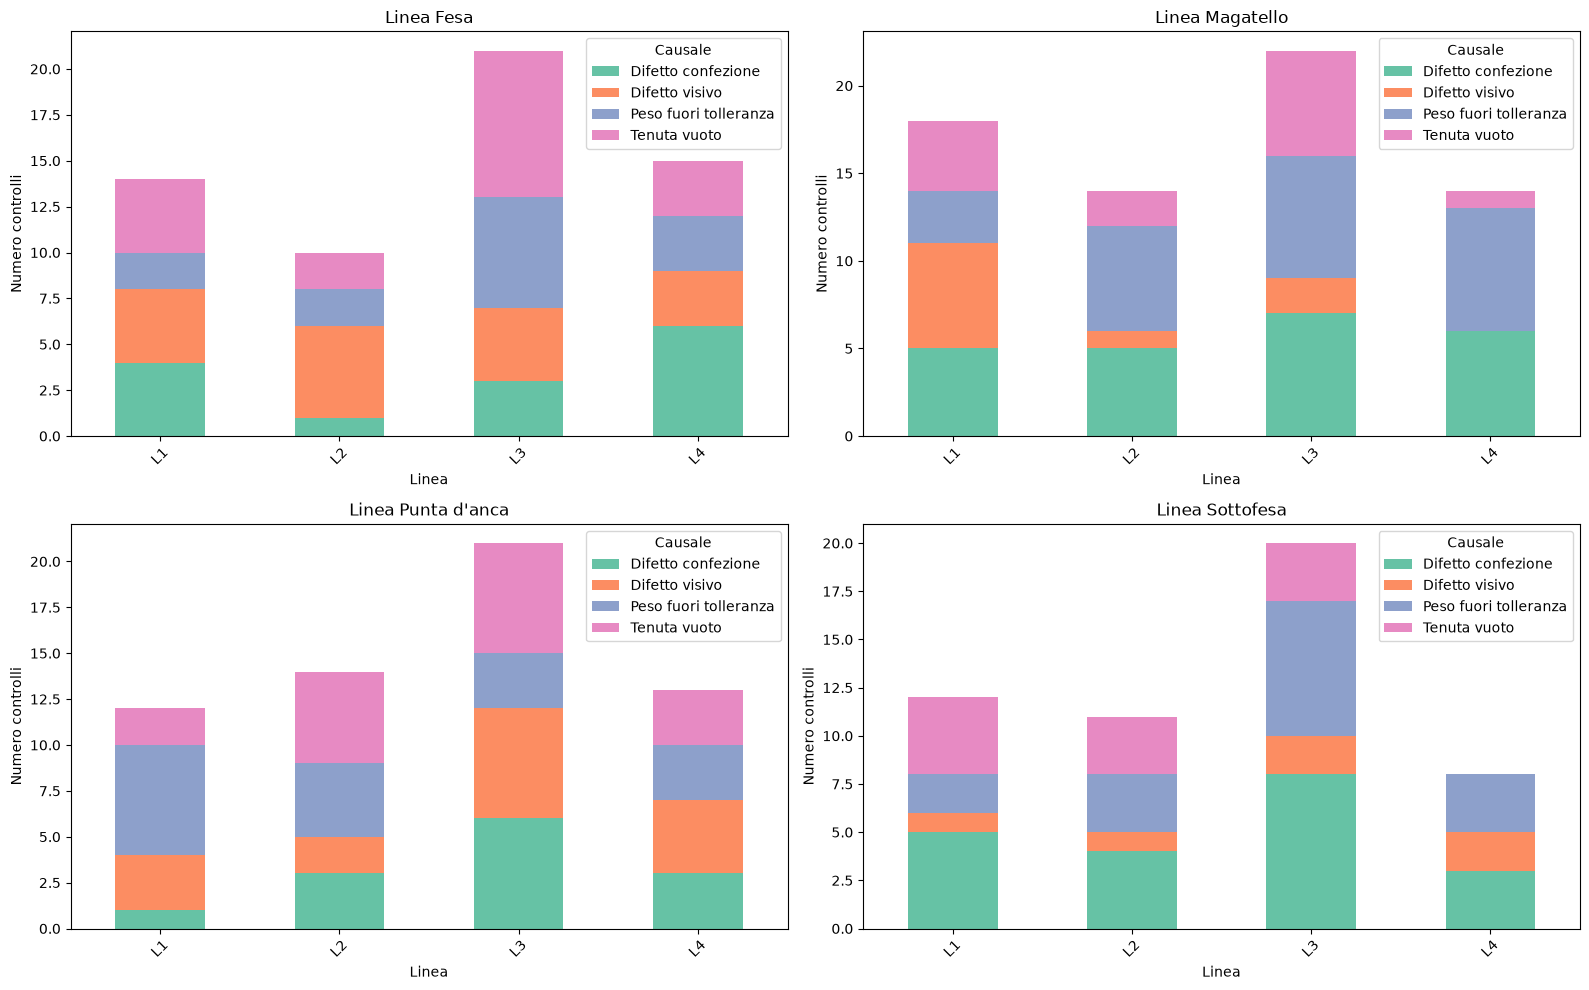

In [109]:
lotti_difettosi_famiglia_group = lotti_difettosi_famiglia.groupby(["famiglia", "linea_id", "causale"])["controllo_id"].count().to_frame().reset_index()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

# Colori per le diverse causali
colori = sns.color_palette("Set2", n_colors=lotti_difettosi_famiglia_group["causale"].nunique())

for ax, famiglia in zip(axes, sorted(lotti_difettosi_famiglia_group["famiglia"].unique())):

    dati_famiglia = lotti_difettosi_famiglia_group[lotti_difettosi_famiglia_group["famiglia"] == famiglia]

    pivot = dati_famiglia.pivot(
        index="linea_id",
        columns="causale",
        values="controllo_id"
    ).fillna(0)

    pivot.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=colori
    )

    ax.set_title(f"Linea {famiglia}")
    ax.set_xlabel("Linea")
    ax.set_ylabel("Numero controlli")
    ax.legend(title="Causale")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

serie temporale (4 grafici affiancati)

In [31]:
lotti_difettosi_famiglia["anno-mese"] = lotti_difettosi_famiglia["data_controllo"].str[:7]
lotti_difettosi_famiglia_group = lotti_difettosi_famiglia.groupby(["anno-mese", "linea_id"])["controllo_id"].count().reset_index()
# lotti_difettosi_famiglia_group

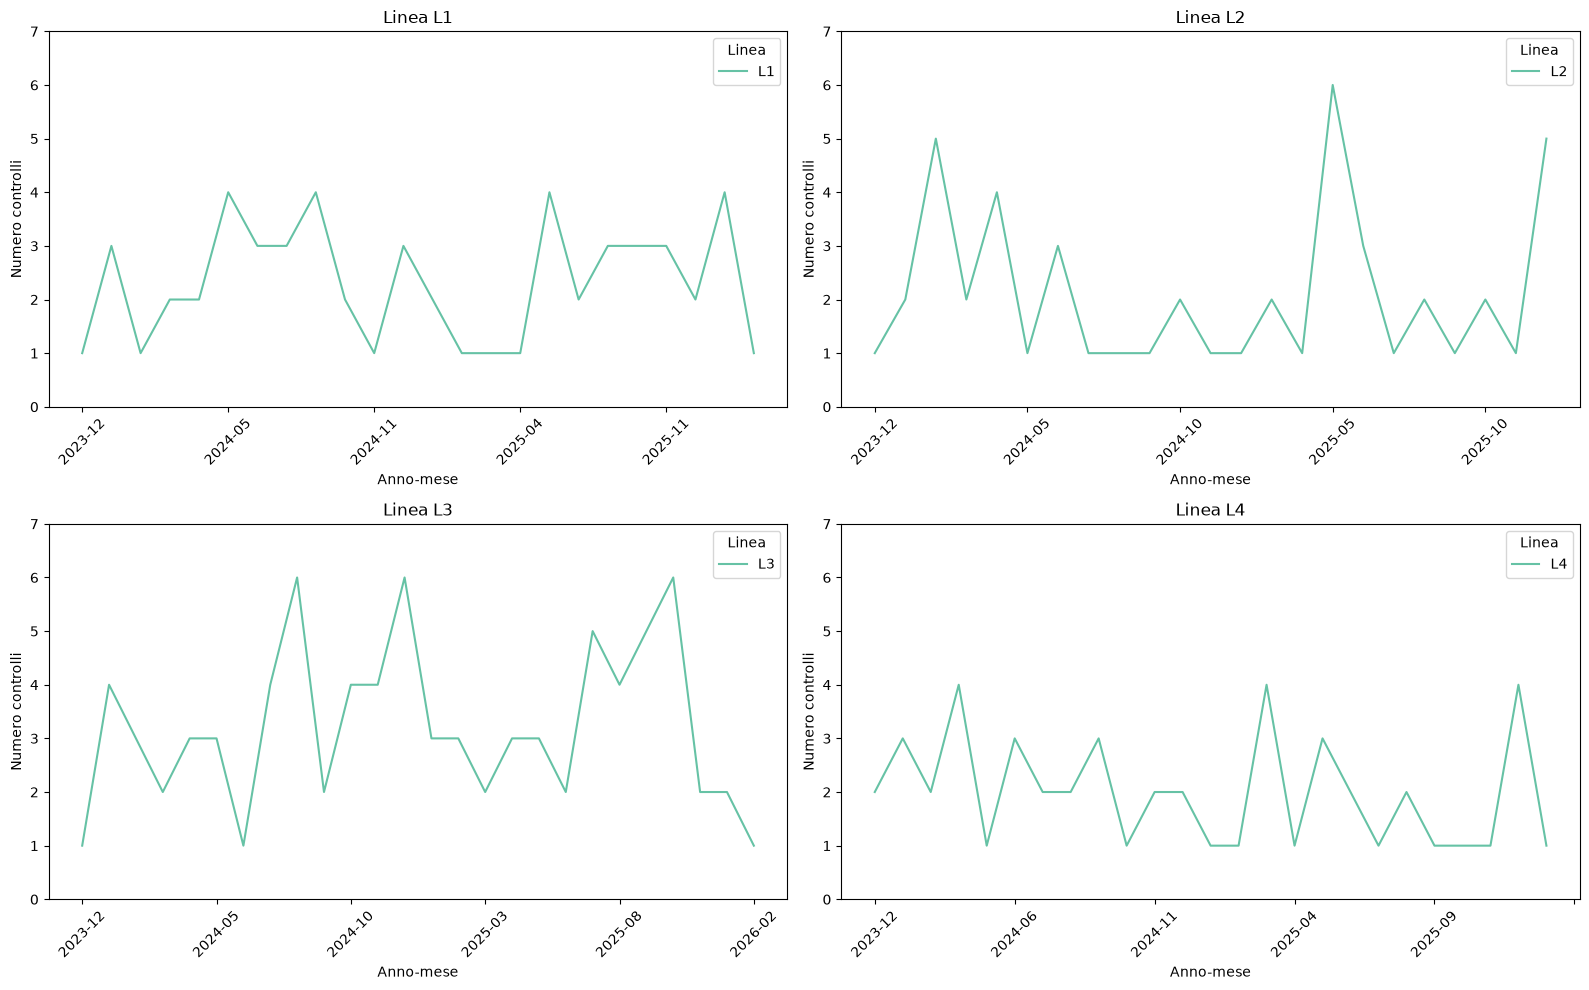

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

y_max = lotti_difettosi_famiglia_group["controllo_id"].max()

# Colori per le diverse causali
colori = sns.color_palette("Set2", n_colors=lotti_difettosi_famiglia_group["linea_id"].nunique())

for ax, linea in zip(axes, sorted(lotti_difettosi_famiglia_group["linea_id"].unique())):

    dati_linea = lotti_difettosi_famiglia_group[lotti_difettosi_famiglia_group["linea_id"] == linea]

    pivot = dati_linea.pivot(
        index="anno-mese",
        columns="linea_id",
        values="controllo_id"
    ).fillna(0)

    pivot.plot(
        kind="line",
        x=None,
        ax=ax,
        color=colori
    )
    ax.set_ylim(0, y_max +1)

    ax.set_title(f"Linea {linea}")
    ax.set_xlabel("Anno-mese")
    ax.set_ylabel("Numero controlli")
    ax.legend(title="Linea")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## Fermi macchina

Fermi macchina

In [33]:
fermi = pd.read_csv("fact_fermi.csv")
# fermi

In [34]:
fermi["anno-mese"] = fermi["data"].str[:7]

In [35]:
fermi_grouped = fermi.groupby(["anno-mese", "linea_id", "causale"]).agg({
                                                        "fermo_id" : "count",
                                                        "durata_minuti" : "sum"
                                                        }).reset_index()
# fermi_grouped

In [36]:
fermi_linee = fermi_grouped.groupby(["linea_id", "causale"]).agg({
                                                                "fermo_id" : "count",
                                                                "durata_minuti" : "sum"
                                                                }).reset_index()
# fermi_linee

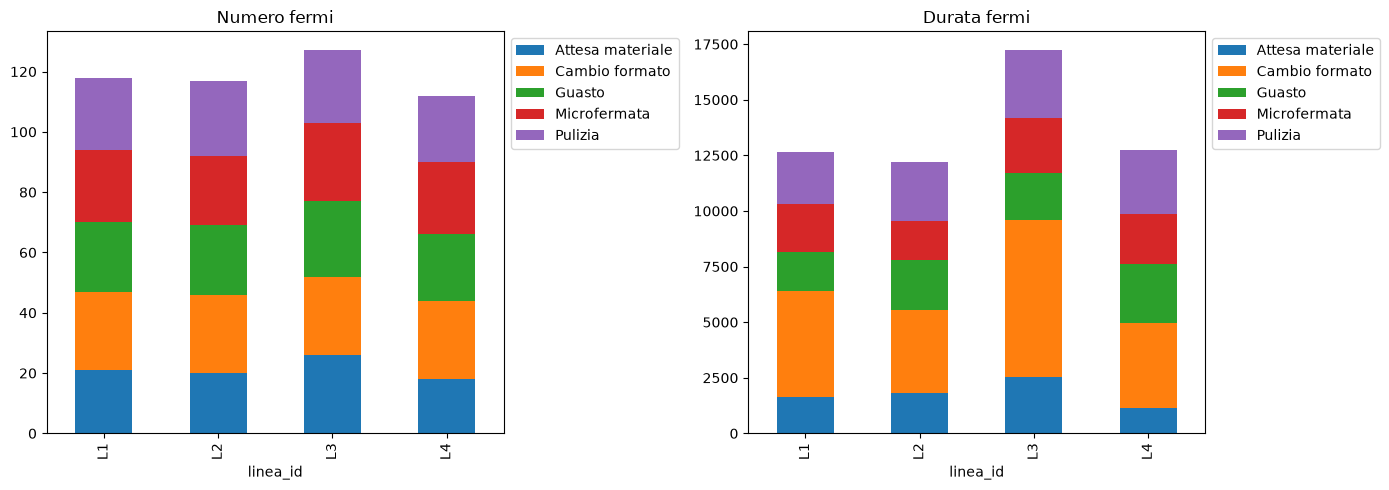

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Sinistra
numero = fermi_linee.pivot(
        index="linea_id",
        columns="causale",
        values="fermo_id"
    ).fillna(0)

numero.plot(
    kind="bar",
    stacked=True, 
    ax=ax1
)

ax1.set_title("Numero fermi")
ax1.legend(bbox_to_anchor=(1, 1), loc="upper left")

# Destra
durata = fermi_linee.pivot(
        index="linea_id",
        columns="causale",
        values="durata_minuti"
    ).fillna(0)

durata.plot(
    kind="bar",
    stacked=True, 
    ax=ax2
)

ax2.set_title("Durata fermi")
ax2.legend(bbox_to_anchor=(1, 1), loc="upper left")


plt.tight_layout()
plt.show()

<Axes: xlabel='anno-mese'>

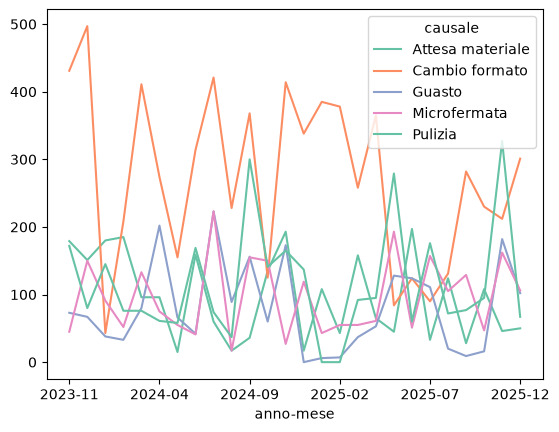

In [38]:
fermi_L3_trend = fermi_grouped.loc[fermi_grouped["linea_id"] == "L3"]
fermi_L3_trend_pivot = fermi_L3_trend.pivot(
        index="anno-mese",
        columns="causale",
        values="durata_minuti"
    ).fillna(0)

fermi_L3_trend_pivot.plot(
        kind="line",
        x=None,
        color=colori
    )

Prodotti con cambio formato più elevato

In [39]:
fermi_prodotti = fermi.merge(prodotti, on="sku", how="left")
fermi_prodotti = fermi_prodotti[["famiglia", "linea_id", "causale", "durata_minuti"]]
# fermi_prodotti

In [40]:
fermi_prodotti_grouped = fermi_prodotti.groupby(["famiglia", "causale"])["durata_minuti"].sum().reset_index()
# fermi_prodotti_grouped

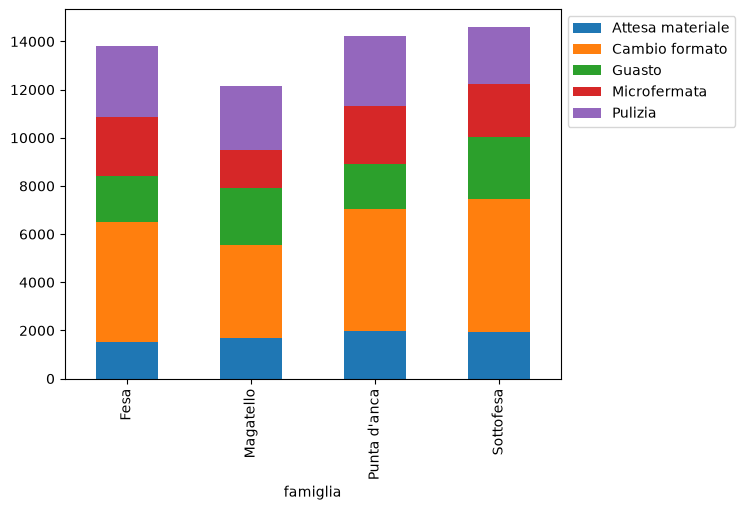

In [41]:
fermi_prodotti_grouped_pivot = fermi_prodotti_grouped.pivot(
        index="famiglia",
        columns="causale",
        values="durata_minuti"
    ).fillna(0)

fermi_prodotti_grouped_pivot.plot(
    kind="bar",
    stacked=True, 
)

plt.legend(bbox_to_anchor=(1,1), loc="upper left")
plt.show()

## Suggerimenti

Studio i costi degli scarti e ipotizzando una resa uguale alle altre linee, vedo quanto potrebbe rendere in più all'anno la linea 3 e quindi quanto potrebbe essere un budget di interventi

In [42]:
df["costo_scarti"] = df["kg_scarto"] * df["costo_materia_prima_kg"]
costo_scarti = df[["sku", "linea_id", "kg_input", "kg_output_conforme", "kg_scarto", "resa_effettiva", "costo_scarti"]]
costo_scarti_plot = costo_scarti.groupby("linea_id")["costo_scarti"].sum().reset_index()
costo_scarti_plot["costo_scarti_annuale"] = costo_scarti_plot["costo_scarti"] / 2
# costo_scarti_plot

<Axes: xlabel='linea_id', ylabel='costo_scarti_annuale'>

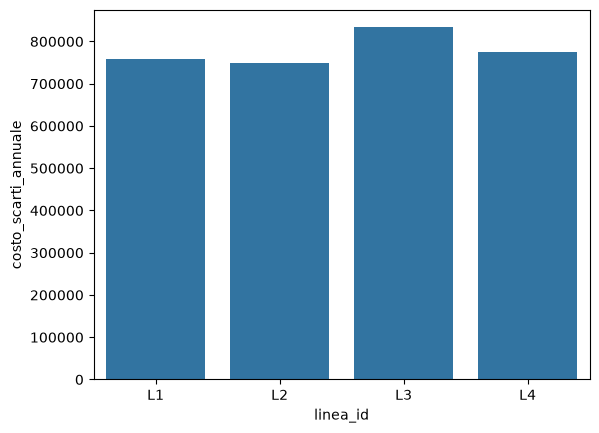

In [43]:
sns.barplot(data=costo_scarti_plot, x="linea_id", y="costo_scarti_annuale")

Quindi se si intervenisse riportando la L3 ai livelli delle altre tre linee si risparmierebbe:

In [44]:
media_annuale_linee = costo_scarti_plot.loc[costo_scarti_plot["linea_id"] != "L3"]["costo_scarti_annuale"].mean()
linea3 = costo_scarti_plot.loc[costo_scarti_plot["linea_id"] == "L3"]["costo_scarti_annuale"].item()
saving = int(linea3 - media_annuale_linee)
print(f"Si potrebbero risparmiare {saving} € all'anno")

Si potrebbero risparmiare 71840 € all'anno


Invece ipotizziamo di spostare:
* la sottofesa da L3 a L4
* la fesa da L4 a L3

I vincoli sono:
* mantenere inalterati i volumi processati per linea
* minimizzare l'aumento di difetti dovuto alla L3

In [49]:
volumi_famiglia = produzione_prodotti.groupby(["linea_id", "famiglia"])[["kg_input", "kg_output_conforme", "kg_scarto"]].sum().reset_index()
volumi_famiglia

,linea_id,famiglia,kg_input,kg_output_conforme,kg_scarto
0,L1,Fesa,196999.59,162237.58,34762.01
1,L1,Magatello,202818.61,167911.08,34907.53
2,L1,Punta d'anca,191874.52,157388.66,34485.86
3,L1,Sottofesa,205019.71,167221.01,37798.70
4,L2,Fesa,202742.20,166887.54,35854.66
5,L2,Magatello,200626.65,165678.87,34947.78
6,L2,Punta d'anca,208484.13,171071.02,37413.11
7,L2,Sottofesa,167901.46,136873.21,31028.25
8,L3,Fesa,199463.51,157314.76,42148.75
9,L3,Magatello,175413.16,144604.99,30808.17


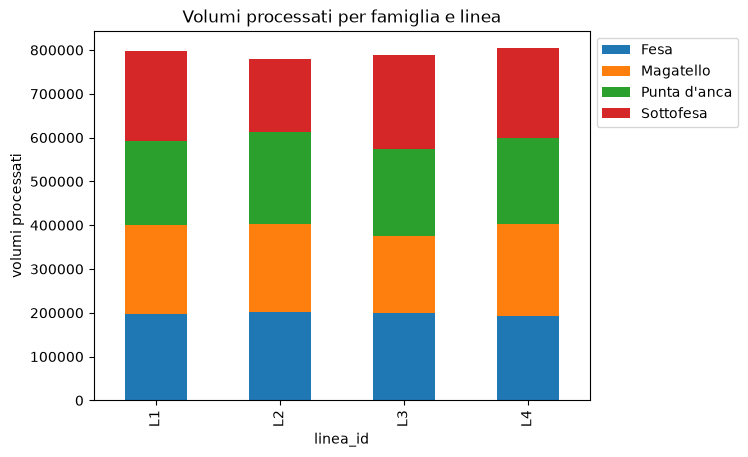

In [51]:
volumi_famiglia_pivot = volumi_famiglia.pivot(
    index="linea_id",
    columns="famiglia",
    values="kg_input"
)

volumi_famiglia_pivot.plot(kind="bar", stacked=True)
plt.ylabel("volumi processati")
plt.title("Volumi processati per famiglia e linea")
plt.legend(bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

In [93]:
candidati_planning = volumi_famiglia.pivot(
    index="famiglia",
    columns="linea_id",
    values="kg_input"
).reset_index()
candidati_planning

linea_id,famiglia,L1,L2,L3,L4
0,Fesa,196999.59,202742.20,199463.51,192509.96
1,Magatello,202818.61,200626.65,175413.16,210842.96
2,Punta d'anca,191874.52,208484.13,200242.31,195861.74
3,Sottofesa,205019.71,167901.46,213052.91,204547.32


In [94]:
# Sposto sottofesa da L3 a L4
candidati_planning["L3 aggiornata"] = np.where(
                                                candidati_planning["famiglia"] == "Sottofesa",
                                                0,
                                                candidati_planning["L3"]
)
candidati_planning["L4 aggiornata"] = np.where(
                                                candidati_planning["famiglia"] == "Sottofesa",
                                                candidati_planning["L3"] + candidati_planning["L4"],
                                                candidati_planning["L4"]
)

# Sposto fesa da L4 a L3
candidati_planning["L3 aggiornata"] = np.where(
                                                candidati_planning["famiglia"] == "Fesa",
                                                candidati_planning["L3"] + candidati_planning["L4"],
                                                candidati_planning["L3 aggiornata"]
)
candidati_planning["L4 aggiornata"] = np.where(
                                                candidati_planning["famiglia"] == "Fesa",
                                                0,
                                                candidati_planning["L4 aggiornata"]
)

candidati_planning.drop(columns=["L3", "L4"], inplace=True)
candidati_planning

linea_id,famiglia,L1,L2,L3 aggiornata,L4 aggiornata
0,Fesa,196999.59,202742.20,391973.47,0.00
1,Magatello,202818.61,200626.65,175413.16,210842.96
2,Punta d'anca,191874.52,208484.13,200242.31,195861.74
3,Sottofesa,205019.71,167901.46,0.00,417600.23


In [100]:
candidati_planning_melt = pd.melt(
    candidati_planning,
    id_vars="famiglia",
    value_vars=["L1", "L2", "L3 aggiornata", "L4 aggiornata"]
)

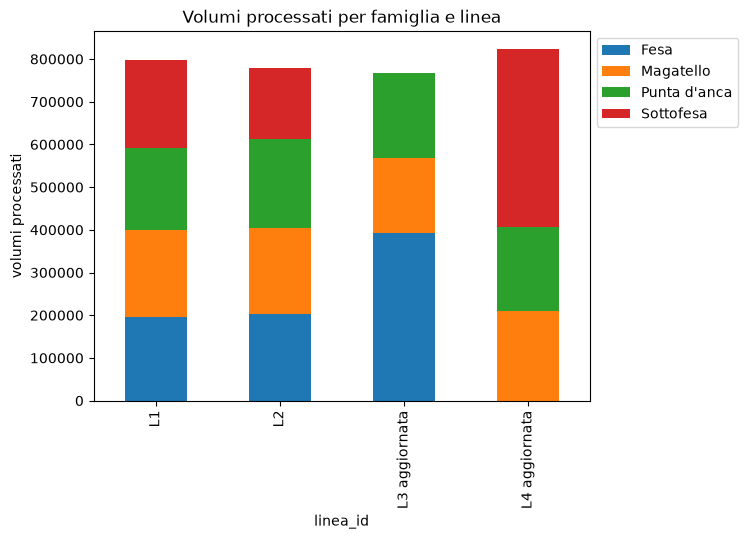

In [103]:
volumi_famiglia_pivot_aggiornata = candidati_planning_melt.pivot(
    index="linea_id",
    columns="famiglia",
    values="value"
)

volumi_famiglia_pivot_aggiornata.plot(kind="bar", stacked=True)
plt.ylabel("volumi processati")
plt.title("Volumi processati per famiglia e linea")
plt.legend(bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

A questo punto, calcolo la % dei lotti difettosi su L3 e L4 per Fesa e Sottofesa.\
Ipotizzando le modifiche al *planning* posso ipotizzare le variazioni sulla difettosità dei lotti 

In [113]:
qualita_famiglia = qualita.merge(prodotti, on="sku", how="left")
qualita_famiglia = qualita_famiglia[["controllo_id", "linea_id", "famiglia", "esito", "causale"]]
qualita_famiglia

,controllo_id,linea_id,famiglia,esito,causale
0,QC00000001,L2,Punta d'anca,Conforme,Nessuna
1,QC00000002,L2,Punta d'anca,Non conforme,Difetto visivo
2,QC00000003,L2,Punta d'anca,Conforme,Nessuna
3,QC00000004,L1,Punta d'anca,Conforme,Nessuna
4,QC00000005,L3,Fesa,Conforme,Nessuna
...,...,...,...,...,...
5500,QC00005501,L2,Sottofesa,Conforme,Nessuna
5501,QC00005502,L4,Punta d'anca,Conforme,Nessuna
5502,QC00005503,L2,Fesa,Conforme,Nessuna
5503,QC00005504,L4,Magatello,Conforme,Nessuna


In [119]:
risultato = (
    qualita_famiglia.groupby(["famiglia", "linea_id"])
      .agg(
          totale=("esito", "size"),
          n_conformi=("esito", lambda x: (x == "Conforme").sum())
      )
      .reset_index()
)

risultato["perc_conformi"] = round((
    risultato["n_conformi"] / risultato["totale"] * 100
), 2)

risultato["perc_non_conformi"] = round(
    100 - risultato["perc_conformi"]
, 2)

risultato

,famiglia,linea_id,totale,n_conformi,perc_conformi,perc_non_conformi
0,Fesa,L1,349,335,95.99,4.01
1,Fesa,L2,336,326,97.02,2.98
2,Fesa,L3,348,327,93.97,6.03
3,Fesa,L4,335,320,95.52,4.48
4,Magatello,L1,370,352,95.14,4.86
5,Magatello,L2,352,338,96.02,3.98
6,Magatello,L3,304,282,92.76,7.24
7,Magatello,L4,369,355,96.21,3.79
8,Punta d'anca,L1,335,323,96.42,3.58
9,Punta d'anca,L2,371,357,96.23,3.77
